# LAB 06 — SVM

**Notebook Google Colab | Học máy ứng dụng | Lab 06**

Nội dung theo tài liệu `Lab06_SVM.pdf`: **phần thực hành theo từng bước + giải 6 bài tập cuối bài**. Các lệnh có chú thích và in kết quả để tiện chụp màn hình.

**Cách sử dụng:** mở tệp `.ipynb` bằng Google Colab → **Runtime → Run all**. Chạy lần lượt từ đầu; dữ liệu CSV được khôi phục tự động trong bước chuẩn bị, không phải tải CSV bằng tay. Ảnh và bảng kết quả được xuất ra thư mục `ket_qua/`. Những kết quả mô hình hoặc thời gian chạy có thể thay đổi theo phiên bản thư viện hoặc máy.

## Chuẩn bị — thư viện, dữ liệu và thư mục kết quả

Bộ dữ liệu lấy trực tiếp từ ZIP người dùng cung cấp, được nhúng vào notebook để mở bằng Colab là chạy được.

In [1]:
# Chuẩn bị dữ liệu gốc đính kèm (tự giải nén, không cần upload riêng).
import base64, io, os, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

_DATA_BASE64 = "UEsDBBQAAAAIADyAPF2FZ7Cc5QcAAGUUAAAXAAAAZGF0YS9oYWlfdmFuZ190cmFuZy5jc3ZVWDmS7cgN9CdibtLTgR2o48iTJVvHF1b+UHvNx0JhSSQS/C/+/Jd+/vPvf/3n77/+gV8ijR/8BWb6gb//gl8P45/8QV8+wX4C3k84tJ/QLwbqD/xa/s0rz4R/+o0yUqddJB8gBY9Zi/fKCGD0Gfw1f2UEQHWMqMQrI/ZszmAdwDg/9D3P31XD9hZiLxMucwJ/GdKD/kF9DmFIhYdv/RD2yCMZyrkqzFZmnd4YUbIx4qDjKr3oBFR8OIdIyhf3TE3fw2aVATXCuYhZXt6MyGOVQjoBgsKX10cdIT5fs8Fa3rFuBsBf/U9P35wxiK6FPdzUA0IVEPmLJ6uUlkD3Yng8F7PghqPRxTHzeeXtK0S8voWD9RNgXN/QJAvxyzKnGhd1k5vSJW5wQsZzkQPTJI7jrIR2LqEOjzdAFWOGsRHhg0pl5uldWqyhIpuXf9ILy2AyDU60YXcp8h2RqCcJ0lfeAeE6Aw0nsEdnVaQLryiXOsJ6wn5FzN/qGg1YbJi3b/CQ1hMkqDMSvghLoPdN2UcxAVFQm+20T+aqemn265eMrJ5kbje5Wr01QNvSJ6Dq6icHDg5sDEocWkyqgSJowU/ScDLH800Qp6yA10MxvthZSTRW4gidzhWqwiNMy+SND7uG6oabhfxtEQT7UkVf76itM0x5Z5qxOLvkfUZxMQedfbK72KGbTFQWpyTdqtGZGDhpNXaGbG/OvCkhkl9qg7hq6Hie8QBOHw6+0nttNLHxXpTVbApIB95QHkO1TGBipf+HKLooght0ZXdIN7NfYyZJNvadlt/4UYeT4Lmqy2BS4JpM/dU9z3QrBmJtl+2aFxrnL4u6idYGCovLulLgbBKMdZZU6+Z4cURDrxJWQNxcJzirxbLfNyDLpDT10FJCtn8zHMLRb5JTFzAvlOk5eOV3WrEFbXrf3ZFhLOnhmwcqS0+GA3SXJYRQa3pyPuRgtn8WhQduBUXUSYr4NrcPRZNsEkBoHjDt+IBpHxq2Sl9JqGfWEQRZ9BFTkE0TFEYKqfJRRGjlifGmBdVAq1MiO9hofcHi6sk/4DJ9XKFlmlfUF3LD/BXYIJCxyVT0SPBZD93XPd3smtAavoXvndfkb3DMvnXOGXeYC+3J7PYWP+id3Wz7HRiuOt5SnF2Ltqsqeg3P7Z7zN6wDmsZ18l2vAPZNjMcbwTPdcMd1QneGgYt/N3kDU3gTYThRUkwmqk5NyqlY3sZk0GMyLI7UmjIy+sNUdmVXyc2uAmzdjqSw+UTpCJIeNjPdQNU2vrh73jNFX2xL5wgpGzkkL5nzP4p/TYNNpnLdWrxRIccplFf6o2lwRm0js1PJ9FmxmvFkcAE+xO3fy8GQYqaC5U8S6hD6lV7Q6OdmTQfoUA+wWnriaT9rbpzy8ZEB71M+6a1XMwLfzYnDCtpoBnjNxOg8Ocs3nSk6pHcqLENrTcHbr/Ka+FAm5uwZ6wfCsOMBMo6yjXHdadCkzCsLcojVNOg+O+qw9GHH6HIJSKPd3qJd3nAJLAuwrFxS3/GtxWHtLKzVMG33Q/mcqyxXV9AyIfNCBS9xqY6aS27o15SZJsp0L8AgJi8w6S7m5qGJpaTKbdMwsOCX/xZ8rgexEhHdSp+a49Ge/iwWYtK8kCjavEjTEWZTLAk/Gd8qUSs9behG8Y9qGb1xmoVbwOekPdHPzf5U/D0MUC3WVpG/ArUIg2+qROE1aS5uokszgnHIVawVl3ms71R01wXSo56YIt7IpxrCpU7oEzk11gpMttOgmTd5Hf4gv3EhBnuNFqqab2lBq4uu3GF2Oqez48rHAFEiqXIfeDOxWTSBgGs41e1AnTZv7CMmEnDHwNKaNPvjO9TTq9Xncn+vNOmd2glg8UHyTeNUFb0v1co1aSi8Fja7KzrI1rcpPq9zs3FL/dGOwFKZ2EL73RqAvVGV7p7kE/YMco7bLmKyFLHdIiliRhtdbnM0dAowbmuB4sfUTHY5CeCxctm3Jc5UT9ftPV/Q1oYOYKUod+r1oFMkJ8lUmwCDPoH8tBXmG8nZe0ULo6T+e6UEWC1ctxMkqxZAoYTYUEh3aHLoMWQuZz2x3qdsGVYc+vUf7aq07Yc1nivJtzgRFsYSltPmiVgdKY+x1YUmzCTD2y99Rk269828RGMZ0RvJKTOapuy6LfV7BZPzZcVkUVwrC/ArhPfCKUanQ1bvtEybTtFhXbFjvyxKL2zyjTBZomW7LwLODU8wO4aPGRvg8Cm/HZ/vSphKv7LtrRu2tYfQv31SCzE1sZZAkn0q6BzNqzGy31aDvlPZPqqjl6GNoNWMmR7jzy7iI8eKzmvVyTeQ+RYn0dkEr4tzgvcqRX6aY9khR8H1cSmUIm/ZfKeRYWK2D5MlDlvc/b/uxj98wd3jmQRYPc/dtXjztvVcrjd80c03HsK3PUoUvQZm1+4DHLWvwqcWZGhK7AQS9JytBC/P9peZlDizlFfrvWlR+b7PeJ8AjGuNyWLW5NvKqcvFeJH0xgp/RPlM8yxa7PTKsDs+315Bnj3ev2q+2oTro8C3gneH1y4YfxDau5h+q/JUT3tWzpzBXlXS2CKJaAePvMMw1ZZUyD3V5TJLBdCNvFywe5NX/uQ1tBADwuPh/qzQC+/nMPX3MJZTVTTSXiU+BpAdt6NuSj7MVzdXW/aKGRJJUUs92aIzfMi+z1KzkYFemD0f/mm9uFCgTjC9kRz/A1BLAwQUAAAACAAyhDhddfmbJOEBAACcBQAAEgAAAGRhdGEvc2luaF92aWVuLmNzdlVUS2pDMQzcB3KT8LDk/2lCoSWEkoQuuujta41k2VmEpwh5NBqNfbu/rq/n5fP+9bje7r8f1++/y8/4PF7P8ykf+RKPcAnnE/XxLeNHI07jW4+KPI04HoQ4jPp8NKnhOOJ2MOI6apqezSgpBilxknQHSpI0S9z9pKBkdO1AQSfmkStHR14gq8acwbIgH8G+GLPRffwfscCxkhde+YioLosByczJ2ASwAUkZL3mJNG2bBFFiQQkaUgNfNi4BStqoSSmWBcgFXCqmSEuBNxTVF2pwAwFVptpugndSzIo9WdfVitCKZjrrGNKITV5aZCom0l2rumQ9fQMZ2M0WM9oF80kBx2BzSJHyJcwEnxBvW9q3lxBDd9a5g/e1beOs6REwdgeHBPZtM0cy+XRPZK1YJ4woL65YsS10W7HESLObfBJjCJynksXuQV0rJra83gmZOxq6a8Blc7PoZA7KBhN83XXakNXLfVFv2xIC6GbTMc/7CQMqdNhUb283WxVdedocFp1ttVi3UZYLorPtComHYMJ36MW2VI9hlPlwqLHce8m817ajyhIMEnY6S1xq4s0PcfkB9rSb0oDO9m6oepPkdj0mel9N4aSsfmCN+yTD65WxN4HW28NrGTZznHMWvwPuun9QSwMEFAAAAAgAPIA8XZANfHHeAgAA/QcAABoAAABkYXRhL3Npbmhfdmllbl9tb19yb25nLmNzdlVVy24dMQjdR8qfWCMMBnu+5ipqo/SqSq4qNYv+fQGDx3cxi2F4HA4H5uP+uD2+ys/7++ft4/79dvv9r/z4db/9vb9/lz/6/vn4en3hgwsdUBgYCry+1FNfRJ/eAUpVQ7OXoxcc4VHVQEedHmYAzcHHKGQeGoKkhnFgaRyGriHDEp/TwB4hpbVV1QytMM2qp9doBet0QDOcmlIYMqXV0CicKR34UFgNJixE/SrHWaSHh1XtaqAROdh7VRjZKzkbor2u1vSDGlubBquISgbhfLfG+KBC0WmVAO44wVNCaWqgYAvBO2mlnbOosWcO/VwRBnMov0+EUxGaBqsB+u6tm8Pw1rGQcPYBPlUMvk8HIaVH5xI1uQYo8T50yMEEtuCbk7ysIVljTl2fDBmOW58YUe0hJUycFORwTrW7thRbT5wTF0anWB1XLTwuB5NarzkPTW/f+Smgr4F056qXnvqeM69T8BPllEka2DGMNUHVkdrB2YQcMjtsScPwGM1Tw1CdLU2SysJQFtUnHFJkbHsmJpQaSzMJ1rIXn1O/PTw8qYs6DOD8qkMQ7lM0utp4WoF2KQVCWwjLA1zhybgfB8NJcM1MnNGY+xl6pRSCO6gaabsP1lmmdEad9m2qNpOea9dDr4txDI9cGiQnmEonThST8XVzJOfKfA3J1iZvCkcRCWmEgPsSMPiy87xaMLfIqOh0HQNTCsd3X20rS41zpuynUmRGkJ8TPRcxIAhV9LhZvmW+Mg2uDLxhCI9aCJ62jErDrfFuRZKrqRtttO4KV4e9cT8RbbHLE0aq4vSJ4Vorb7VvJ953wqSGwldVcSHB2sSm7422Xi2F5Ahnr3rXAnhzbWqErIjQCS5ZTMFzCAcpBJ/K8t21wrDR1+yuJVu57pQ5zzg5A2CJ01DQ879qu/ngEahD23TA9qMJj+Y7xUsGw1PqQY+/SI2/DMbFx5BNy8MpUbJtV82PR+qGYwfzkP4HUEsBAhQAFAAAAAgAPIA8XYVnsJzlBwAAZRQAABcAAAAAAAAAAAAAALaBAAAAAGRhdGEvaGFpX3ZhbmdfdHJhbmcuY3N2UEsBAhQAFAAAAAgAMoQ4XXX5myThAQAAnAUAABIAAAAAAAAAAAAAALaBGggAAGRhdGEvc2luaF92aWVuLmNzdlBLAQIUABQAAAAIADyAPF2QDXxx3gIAAP0HAAAaAAAAAAAAAAAAAAC2gSsKAABkYXRhL3Npbmhfdmllbl9tb19yb25nLmNzdlBLBQYAAAAAAwADAM0AAABBDQAAAAA="
with zipfile.ZipFile(io.BytesIO(base64.b64decode(_DATA_BASE64))) as z:
    for item in z.infolist():
        target = Path(item.filename)
        if target.is_absolute() or '..' in target.parts:
            raise ValueError('Duong dan ZIP khong an toan')
        z.extract(item, '.')
Path('ket_qua').mkdir(exist_ok=True)
print('Da nap:', sorted(str(p) for p in Path('data').glob('*')))
print('Phien ban sklearn:')
import sklearn
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)  # Giảm độ trễ BLAS khi huấn luyện trên CPU Colab
print(sklearn.__version__)

Da nap: ['data/hai_vang_trang.csv', 'data/sinh_vien.csv', 'data/sinh_vien_mo_rong.csv']
Phien ban sklearn:
1.6.1


## Phần I — Thực hành 5 bước theo tài liệu

### Bước 1 (mục 2): SVM tuyến tính, đường có lề rộng nhất và vectơ hỗ trợ

Phuong trinh: -0.8314*x1 + -0.3549*x2 + 4.8204 = 0
Do rong le: 2.2126 | So vecto ho tro: 3
Support 18 : [5.201 4.217] nhan 0 f= -1.0001
Support 10 : [2.881 4.017] nhan 1 f= 0.9999
Support 13 : [3.588 2.36 ] nhan 1 f= 1.0002
Hoc lai tu vector ho tro: [[-0.8313 -0.3552]] [4.8214]
Diem moi, gia tri f(x), nhan du doan: [([3.0, 3.0], np.float64(1.2617), np.int64(1)), ([5.0, 4.5], np.float64(-0.9333), np.int64(0))]


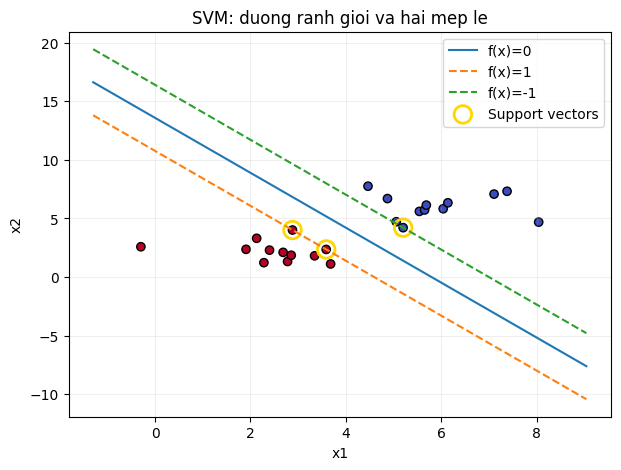

In [2]:
from sklearn.datasets import make_blobs
from sklearn.svm import SVC
X_blobs, y_blobs = make_blobs(n_samples=24, centers=[[2,2],[6,6]], cluster_std=0.9, random_state=0)
y_blobs = 1-y_blobs
svm_linear = SVC(kernel='linear', C=1000).fit(X_blobs, y_blobs)
w, b = svm_linear.coef_[0], float(svm_linear.intercept_[0])
width=2/np.linalg.norm(w)
print(f'Phuong trinh: {w[0]:.4f}*x1 + {w[1]:.4f}*x2 + {b:.4f} = 0')
print('Do rong le:', round(width,4),'| So vecto ho tro:',len(svm_linear.support_))
for idx in svm_linear.support_:
    print('Support',idx,':',np.round(X_blobs[idx],3),'nhan',y_blobs[idx], 'f=',round(svm_linear.decision_function(X_blobs[idx:idx+1])[0],4))
svm_only = SVC(kernel='linear',C=1000).fit(X_blobs[svm_linear.support_],y_blobs[svm_linear.support_])
print('Hoc lai tu vector ho tro:', np.round(svm_only.coef_,4),np.round(svm_only.intercept_,4))
new_points = np.array([[3,3],[5,4.5]])
print('Diem moi, gia tri f(x), nhan du doan:',list(zip(new_points.tolist(),svm_linear.decision_function(new_points).round(4),svm_linear.predict(new_points))))
xx=np.linspace(X_blobs[:,0].min()-1,X_blobs[:,0].max()+1,200)
plt.figure(figsize=(7,5));plt.scatter(*X_blobs.T,c=y_blobs,cmap='coolwarm',edgecolor='black')
for fval,sty in [(0,'-'),(1,'--'),(-1,'--')]:
    plt.plot(xx,(-w[0]*xx-b+fval)/w[1],sty,label=f'f(x)={fval}')
plt.scatter(*X_blobs[svm_linear.support_].T,s=160,facecolors='none',edgecolors='gold',linewidths=2,label='Support vectors')
plt.xlabel('x1');plt.ylabel('x2');plt.legend();plt.title('SVM: duong ranh gioi va hai mep le');plt.grid(alpha=.2)
plt.savefig('ket_qua/lab06_buoc1_svm.png',dpi=150,bbox_inches='tight');plt.show()

### Bước 2 (mục 3): Tham số C và ảnh hưởng của chuẩn hóa

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
sv=pd.read_csv('data/sinh_vien.csv')
Xs_tr,Xs_te,ys_tr,ys_te=train_test_split(sv[['gio_on','diem_giua_ky']],sv['qua_mon'],test_size=.25,random_state=17,stratify=sv['qua_mon'])
rows=[]
for C in [.01,.1,1,10,100]:
    mdl=make_pipeline(StandardScaler(),SVC(kernel='linear',C=C)).fit(Xs_tr,ys_tr)
    rows.append([C,len(mdl[-1].support_),2/np.linalg.norm(mdl[-1].coef_[0]),mdl.score(Xs_tr,ys_tr),mdl.score(Xs_te,ys_te)])
display(pd.DataFrame(rows,columns=['C','So support vectors','Do rong le (chuan hoa)','Accuracy train','Accuracy test']).round(4))
sv3=pd.read_csv('data/sinh_vien_mo_rong.csv'); X3=sv3.drop(columns='qua_mon');y3=sv3.qua_mon
X3tr,X3te,y3tr,y3te=train_test_split(X3,y3,test_size=.25,random_state=17,stratify=y3)
for name,model in [('Khong chuan hoa',SVC()),('Co chuan hoa',make_pipeline(StandardScaler(),SVC()))]:
    print(name,':',round(model.fit(X3tr,y3tr).score(X3te,y3te),4))
print('Nhan xet: C nho cho le rong; don vi cot qua lech can chuan hoa.')

,C,So support vectors,Do rong le (chuan hoa),Accuracy train,Accuracy test
0,0.01,74,3.8414,0.8556,0.8667
1,0.10,44,1.7033,0.8889,0.9000
2,1.00,31,1.2879,0.8778,0.9000
3,10.00,28,1.0648,0.9000,0.9000
4,100.00,27,1.0496,0.9000,0.9000


Khong chuan hoa : 0.6
Co chuan hoa : 0.9
Nhan xet: C nho cho le rong; don vi cot qua lech can chuan hoa.


### Bước 3 (mục 4): Nâng chiều thủ công và kernel cho hai vầng trăng

Nguong 1D tot nhat: 0.7142857142857143 | Them cot x^2: 1.0
Linear SVM    test accuracy = 0.8667
Poly bac 3    test accuracy = 0.8667
RBF SVM       test accuracy = 0.9200
Logistic      test accuracy = 0.8533
KNN 13        test accuracy = 0.9200
So support vectors RBF: 89


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


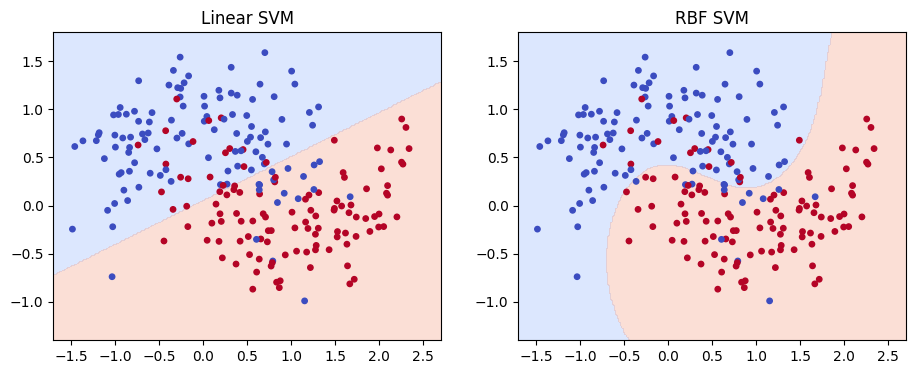

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
x=np.array([-4.,-3.4,-2.8,-2.2,-1.2,-.7,-.2,.3,.8,1.3,2.3,2.9,3.5,4.]); yx=(np.abs(x)<1.8).astype(int)
score_1d=max(np.mean((x<=t).astype(int)==yx) for t in x)
score_2d=SVC(kernel='linear',C=1000).fit(np.c_[x,x**2],yx).score(np.c_[x,x**2],yx)
print('Nguong 1D tot nhat:',score_1d,'| Them cot x^2:',score_2d)
moons=pd.read_csv('data/hai_vang_trang.csv')
Xm_tr,Xm_te,ym_tr,ym_te=train_test_split(moons[['x1','x2']],moons.nhan,test_size=.25,random_state=17,stratify=moons.nhan)
models={'Linear SVM':SVC(kernel='linear'),'Poly bac 3':SVC(kernel='poly',degree=3),'RBF SVM':SVC(kernel='rbf'),'Logistic':LogisticRegression(),'KNN 13':KNeighborsClassifier(13)}
for name,model in models.items():
    model.fit(Xm_tr,ym_tr)
    print(f'{name:13s} test accuracy = {model.score(Xm_te,ym_te):.4f}')
print('So support vectors RBF:',len(models['RBF SVM'].support_))
xx1,xx2=np.meshgrid(np.linspace(-1.7,2.7,250),np.linspace(-1.4,1.8,250))
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,name in zip(axs,['Linear SVM','RBF SVM']):
    Z=models[name].predict(np.c_[xx1.ravel(),xx2.ravel()]).reshape(xx1.shape)
    ax.contourf(xx1,xx2,Z,levels=[-.5,.5,1.5],alpha=.3,cmap='coolwarm')
    ax.scatter(Xm_tr['x1'],Xm_tr['x2'],c=ym_tr,cmap='coolwarm',s=15)
    ax.set_title(name)
plt.savefig('ket_qua/lab06_buoc3_kernels.png',dpi=150,bbox_inches='tight');plt.show()

### Bước 4 (mục 5): Khảo sát gamma và dò lưới C–gamma

In [5]:
from sklearn.model_selection import GridSearchCV
for gamma in [.1,1,10,100]:
    model=SVC(kernel='rbf',gamma=gamma).fit(Xm_tr,ym_tr)
    print(f'gamma={gamma:>5}, train={model.score(Xm_tr,ym_tr):.4f}, test={model.score(Xm_te,ym_te):.4f}, SV={len(model.support_)}')
grid_svm=GridSearchCV(SVC(kernel='rbf'),{'C':[.1,1,10,100],'gamma':[.01,.1,1,10]},cv=5)
grid_svm.fit(Xm_tr,ym_tr)
cv=pd.DataFrame(grid_svm.cv_results_['params']);cv['CV score']=grid_svm.cv_results_['mean_test_score']
display(cv.pivot(index='C',columns='gamma',values='CV score').round(4))
print('Best:',grid_svm.best_params_,'CV:',round(grid_svm.best_score_,4),'Test:',round(grid_svm.score(Xm_te,ym_te),4))

gamma=  0.1, train=0.8356, test=0.8533, SV=113
gamma=    1, train=0.8711, test=0.9200, SV=88
gamma=   10, train=0.8978, test=0.9067, SV=128
gamma=  100, train=0.9422, test=0.8133, SV=217


gamma,0.01,0.10,1.00,10.00
C,,,,
0.1,0.6578,0.8044,0.8444,0.8578
1.0,0.8044,0.8178,0.8667,0.8667
10.0,0.8178,0.8400,0.8711,0.8311
100.0,0.8178,0.8533,0.8711,0.7467


Best: {'C': 10, 'gamma': 1} CV: 0.8711 Test: 0.92


### Bước 5 (mục 6): Nhận dạng chữ số viết tay với SVM

So anh: (1797, 64) | SVM accuracy: 0.9911111111111112 | Doan sai: 4
Danh sach sai (index,that,doan): [(6, 9, 3), (18, 8, 1), (161, 4, 8), (428, 7, 9)]
SVM chuan hoa 0.9778
KNN 5 0.9867
Logistic chuan hoa 0.9711


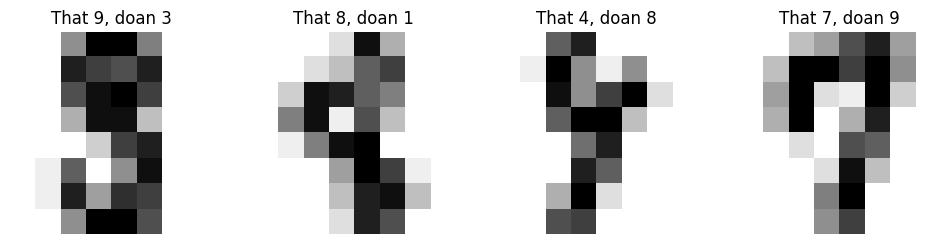

In [6]:
from sklearn.datasets import load_digits
Xd,yd=load_digits(return_X_y=True)
Xd_tr,Xd_te,yd_tr,yd_te=train_test_split(Xd,yd,test_size=.25,random_state=17,stratify=yd)
svm_digit=SVC(kernel='rbf').fit(Xd_tr,yd_tr)
pred_digit=svm_digit.predict(Xd_te)
errors=np.flatnonzero(pred_digit!=yd_te)
print('So anh:',Xd.shape,'| SVM accuracy:',accuracy_score(yd_te,pred_digit),'| Doan sai:',len(errors))
print('Danh sach sai (index,that,doan):',[(int(i),int(yd_te[i]),int(pred_digit[i])) for i in errors])
for name,model in {'SVM chuan hoa':make_pipeline(StandardScaler(),SVC()),'KNN 5':KNeighborsClassifier(),'Logistic chuan hoa':make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000))}.items():
    print(name, round(model.fit(Xd_tr,yd_tr).score(Xd_te,yd_te),4))
fig,ax=plt.subplots(1,max(1,len(errors)),figsize=(3*max(1,len(errors)),3));ax=np.atleast_1d(ax)
for a,i in zip(ax,errors):
    a.imshow(Xd_te[i].reshape(8,8),cmap='gray_r');a.set_title(f'That {yd_te[i]}, doan {pred_digit[i]}');a.axis('off')
plt.savefig('ket_qua/lab06_buoc5_chu_so_sai.png',dpi=150,bbox_inches='tight');plt.show()

## Phần II — Giải 6 bài tập Lab 06

### Bài tập 1 — Tự tính f(x) và khoảng cách đến đường phân chia

In [7]:
# Không gọi decision_function cho hai điểm theo yêu cầu.
points=np.array([[3.,3.],[5.,4.5]])
fx=points@w+b
norm_w=np.sqrt((w**2).sum())
for p,f in zip(points,fx):
    print(f'Diem {tuple(p)}: f(x)={f:.4f}, khoang cach={abs(f)/norm_w:.4f}')
print('Khoang cach cua 3 support vectors:')
for idx in svm_linear.support_:
    f=float(X_blobs[idx]@w+b)
    print(f'  diem {idx}: |f|/||w|| = {abs(f)/norm_w:.4f}')
print('Nua do rong le:',width/2)
print('Giai thich: tai cac support vectors tren mep le |f(x)|=1, nen khoang cach = 1/||w|| = nua do rong le.')

Diem (np.float64(3.0), np.float64(3.0)): f(x)=1.2617, khoang cach=1.3958
Diem (np.float64(5.0), np.float64(4.5)): f(x)=-0.9333, khoang cach=1.0325
Khoang cach cua 3 support vectors:
  diem 18: |f|/||w|| = 1.1064
  diem 10: |f|/||w|| = 1.1062
  diem 13: |f|/||w|| = 1.1065
Nua do rong le: 1.1062823884231796
Giai thich: tai cac support vectors tren mep le |f(x)|=1, nen khoang cach = 1/||w|| = nua do rong le.


### Bài tập 2 — Thêm điểm mới rồi so đường ranh giới

In [8]:
def fit_added(point):
    xx=np.vstack([X_blobs,np.asarray(point).reshape(1,2)])
    yy=np.append(y_blobs,1)
    mm=SVC(kernel='linear',C=1000).fit(xx,yy)
    return mm
for label,p in [('Diem rat xa',[-1.,-1.]),('Diem gan ranh gioi',[4.5,4.])]:
    mm=fit_added(p)
    print(label,': w=',np.round(mm.coef_[0],4),'b=',np.round(mm.intercept_[0],4),'| thay doi w=',np.linalg.norm(mm.coef_[0]-w).round(6),'| support=',mm.support_.tolist())
print('Ket luan: diem xa le thuong khong anh huong; diem gan hay vi pham le co the thanh support vector, lam doi ranh gioi.')

Diem rat xa : w= [-0.8314 -0.3549] b= 4.8204 | thay doi w= 0.0 | support= [18, 10, 13]
Diem gan ranh gioi : w= [-2.603  -0.8068] b= 15.9409 | thay doi w= 1.828401 | support= [18, 24]
Ket luan: diem xa le thuong khong anh huong; diem gan hay vi pham le co the thanh support vector, lam doi ranh gioi.


### Bài tập 3 — Kernel đa thức với GridSearchCV

In [9]:
rows=[]; poly_results={}
for degree in [2,3,4]:
    search=GridSearchCV(make_pipeline(StandardScaler(),SVC(kernel='poly',degree=degree)),{'svc__C':[.1,1,10,100]},cv=5)
    search.fit(Xm_tr,ym_tr)
    poly_results[degree]=search
    rows.append({'degree':degree,'C':search.best_params_['svc__C'],'CV':search.best_score_,'test':search.score(Xm_te,ym_te)})
result=pd.DataFrame(rows);display(result.round(4))
best_d=result.loc[result.CV.idxmax(),'degree']
print('Bac poly tot nhat theo CV:',int(best_d),'| RBF (buoc 4) test:',round(grid_svm.score(Xm_te,ym_te),4))
print('Nhan xet: chi so CV dung chon tham so, tap kiem tra chi dung de so sanh sau cung.')

,degree,C,CV,test
0,2,1,0.5422,0.5067
1,3,1,0.8178,0.8267
2,4,100,0.5156,0.4800


Bac poly tot nhat theo CV: 3 | RBF (buoc 4) test: 0.92
Nhan xet: chi so CV dung chon tham so, tap kiem tra chi dung de so sanh sau cung.


### Bài tập 4 — Dò lưới mịn quanh tham số tốt nhất

In [10]:
fine=GridSearchCV(SVC(kernel='rbf'),{'C':[3,10,30],'gamma':[.3,1,3]},cv=5).fit(Xm_tr,ym_tr)
print('Best:',fine.best_params_,'| CV fine=',round(fine.best_score_,4),'| CV goc=',round(grid_svm.best_score_,4))
print('Test fine=',round(fine.score(Xm_te,ym_te),4),'| Test goc=',round(grid_svm.score(Xm_te,ym_te),4))
print('Nhan xet: do min chi co loi neu CV thuc su tang, khong nen chon theo accuracy cua tap test.')

Best: {'C': 30, 'gamma': 1} | CV fine= 0.8756 | CV goc= 0.8711
Test fine= 0.92 | Test goc= 0.92
Nhan xet: do min chi co loi neu CV thuc su tang, khong nen chon theo accuracy cua tap test.


### Bài tập 5 — Ma trận nhầm lẫn 10×10 và lưu từng ảnh đoán sai

In [11]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(yd_te,pred_digit,labels=list(range(10)))
display(pd.DataFrame(cm,index=[f'That {i}' for i in range(10)],columns=[f'Doan {i}' for i in range(10)]))
for i in errors:
    fig,ax=plt.subplots(figsize=(2.4,2.4))
    ax.imshow(Xd_te[i].reshape(8,8),cmap='gray_r');ax.axis('off');ax.set_title(f'That {yd_te[i]} - Doan {pred_digit[i]}')
    path=f'ket_qua/lab06_chu_so_sai_{i}_that_{yd_te[i]}_doan_{pred_digit[i]}.png'
    fig.savefig(path,dpi=180,bbox_inches='tight');plt.close(fig)
print('Cac cap nham:',[(int(yd_te[i]),int(pred_digit[i])) for i in errors])
print('Nhan xet: cac net viet mo, thieu net hoac hinh dang gan nhau khien mo hinh nham.')

,Doan 0,Doan 1,Doan 2,Doan 3,Doan 4,Doan 5,Doan 6,Doan 7,Doan 8,Doan 9
That 0,45,0,0,0,0,0,0,0,0,0
That 1,0,46,0,0,0,0,0,0,0,0
That 2,0,0,44,0,0,0,0,0,0,0
That 3,0,0,0,46,0,0,0,0,0,0
That 4,0,0,0,0,44,0,0,0,1,0
That 5,0,0,0,0,0,46,0,0,0,0
That 6,0,0,0,0,0,0,45,0,0,0
That 7,0,0,0,0,0,0,0,44,0,1
That 8,0,1,0,0,0,0,0,0,42,0
That 9,0,0,0,1,0,0,0,0,0,44


Cac cap nham: [(9, 3), (8, 1), (4, 8), (7, 9)]
Nhan xet: cac net viet mo, thieu net hoac hinh dang gan nhau khien mo hinh nham.


### Bài tập 6 — Thời gian học SVC và LinearSVC trên dữ liệu lớn

Dùng thời gian thực tế của Colab; số liệu phụ thuộc máy và phiên chạy.

In [ ]:
import time
from sklearn.datasets import make_classification
from sklearn.svm import LinearSVC
times=[]
for n in [2000,5000,10000,20000]:
    Xbig,ybig=make_classification(n_samples=n,n_features=20,random_state=0)
    row={'n':n}
    for name,model in [('SVC',SVC()),('LinearSVC',LinearSVC(dual=False,max_iter=5000,random_state=0))]:
        t0=time.perf_counter();model.fit(Xbig,ybig)
        row[name+' (s)']=time.perf_counter()-t0
    times.append(row)
bench=pd.DataFrame(times)
for col in ['SVC (s)','LinearSVC (s)']:
    bench[col+' / truoc']=bench[col]/bench[col].shift()
display(bench.round(4))
print('Nhan xet: LinearSVC thuong mo rong tot hon voi n lon; so sanh he so tang thoi gian o hai cot cuoi.')